In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split

# Add project root to Python's import path
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

# Import our reusable modules
from src.dataset import WaterDataset
from src.model import (
    WaterPotabilityNN,
    WaterPotabilityNN_BN,
    WaterPotabilityNN_BN_Dropout
)
from src.train import train_model
from src.evaluate import evaluate_model

print("All imports successful!")

All imports successful!


In [2]:
# Load the training dataset
df = pd.read_csv(project_root / "data" / "water_train.csv")

# Reproduce the original training/validation split
df_train, df_val = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["Potability"]
)

# Create PyTorch datasets
train_dataset = WaterDataset(df_train)
val_dataset = WaterDataset(df_val)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Input features:", train_dataset[0][0].shape[0])

Training samples: 1206
Validation samples: 302
Input features: 9


In [3]:
from torch.utils.data import DataLoader

batch_size = 32

def create_dataloaders(seed=42):
    # Control the order of shuffled training samples
    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    return train_loader, val_loader


# Test the function
train_loader, val_loader = create_dataloaders()

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 38
Validation batches: 10


In [4]:
experiments = {
    "Baseline DNN": {
        "model_class": WaterPotabilityNN,
        "weight_decay": 0.0
    },
    "BatchNorm DNN": {
        "model_class": WaterPotabilityNN_BN,
        "weight_decay": 0.0
    },
    "BatchNorm + Dropout": {
        "model_class": WaterPotabilityNN_BN_Dropout,
        "weight_decay": 0.0
    },
    "DNN + Weight Decay": {
        "model_class": WaterPotabilityNN,
        "weight_decay": 0.001
    }
}

# Verify the configurations
for name, config in experiments.items():
    print(f"{name}: weight_decay={config['weight_decay']}")

Baseline DNN: weight_decay=0.0
BatchNorm DNN: weight_decay=0.0
BatchNorm + Dropout: weight_decay=0.0
DNN + Weight Decay: weight_decay=0.001


In [5]:
# Store experiment results
experiment_results = []
trained_models = {}
training_histories = {}

for name, config in experiments.items():

    print(f"\n{'=' * 50}")
    print(f"Experiment: {name}")
    print(f"{'=' * 50}")

    # Reproducibility
    torch.manual_seed(42)

    train_loader, val_loader = create_dataloaders(seed=42)

    # Create a fresh model
    model = config["model_class"]()

    # Loss function and optimiser
    criterion = nn.BCEWithLogitsLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=config["weight_decay"]
    )

    # Train with early stopping
    model, train_losses, val_losses = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        criterion=criterion,
        optimizer=optimizer,
        num_epochs=50,
        patience=7
    )

    # Evaluate on validation data
    metrics = evaluate_model(
        model=model,
        data_loader=val_loader,
        threshold=0.5
    )

    # Store results
    experiment_results.append({
        "Model": name,
        "Validation Loss": min(val_losses),
        "Accuracy": metrics["accuracy"],
        "Macro F1": metrics["macro_f1"],
        "ROC-AUC": metrics["roc_auc"]
    })

    trained_models[name] = model

    training_histories[name] = {
        "train": train_losses,
        "val": val_losses
    }

# Display comparison table
results_df = pd.DataFrame(experiment_results)

display(results_df.round(4))


Experiment: Baseline DNN
Epoch 5/50 | Train: 0.6732 | Val: 0.6729
Epoch 10/50 | Train: 0.6692 | Val: 0.6697
Epoch 15/50 | Train: 0.6622 | Val: 0.6639
Epoch 20/50 | Train: 0.6496 | Val: 0.6636
Epoch 25/50 | Train: 0.6358 | Val: 0.6465
Epoch 30/50 | Train: 0.6233 | Val: 0.6402
Epoch 35/50 | Train: 0.6078 | Val: 0.6372
Epoch 40/50 | Train: 0.5989 | Val: 0.6189
Epoch 45/50 | Train: 0.5850 | Val: 0.6124
Epoch 50/50 | Train: 0.5806 | Val: 0.6111
Best epoch: 49
Best validation loss: 0.6095
              precision    recall  f1-score   support

 Not Potable       0.68      0.90      0.77       181
     Potable       0.70      0.36      0.48       121

    accuracy                           0.68       302
   macro avg       0.69      0.63      0.62       302
weighted avg       0.69      0.68      0.65       302

ROC-AUC: 0.6874

Confusion Matrix:
[[162  19]
 [ 77  44]]

Experiment: BatchNorm DNN
Epoch 5/50 | Train: 0.6019 | Val: 0.6121
Epoch 10/50 | Train: 0.5492 | Val: 0.6125
Early stopping a

,Model,Validation Loss,Accuracy,Macro F1,ROC-AUC
0,Baseline DNN,0.6095,0.6821,0.6248,0.6874
1,BatchNorm DNN,0.6100,0.6854,0.6178,0.6909
2,BatchNorm + Dropout,0.6054,0.6689,0.6068,0.6967
3,DNN + Weight Decay,0.6300,0.6523,0.5804,0.6626


In [6]:
from sklearn.metrics import confusion_matrix
import pandas as pd
import torch

safety_results = []

for name, model in trained_models.items():
    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for features, labels in val_loader:
            logits = model(features)
            predictions = (logits.view(-1) >= 0).int()

            y_true.extend(labels.int().tolist())
            y_pred.extend(predictions.tolist())

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    safety_results.append({
        "Model": name,
        "Unsafe → Safe (FP)": fp,
        "Safe → Unsafe (FN)": fn,
        "Correctly Safe (TP)": tp,
        "Correctly Unsafe (TN)": tn
    })

safety_df = pd.DataFrame(safety_results)
display(safety_df)

,Model,Unsafe → Safe (FP),Safe → Unsafe (FN),Correctly Safe (TP),Correctly Unsafe (TN)
0,Baseline DNN,19,77,44,162
1,BatchNorm DNN,14,81,40,167
2,BatchNorm + Dropout,20,80,41,161
3,DNN + Weight Decay,20,85,36,161


In [7]:
# Select the final model
final_model = trained_models["BatchNorm DNN"]

# Save its weights
model_path = project_root / "models" / "final_batchnorm_dnn.pt"

torch.save(final_model.state_dict(), model_path)

print(f"Final model saved to: {model_path}")

Final model saved to: c:\Users\sy_be\Projects\Water-Potability-PyTorch\models\final_batchnorm_dnn.pt


In [8]:
# Load the untouched test dataset
df_test = pd.read_csv(
    project_root / "data" / "water_test.csv"
)

# Create the PyTorch test dataset
test_dataset = WaterDataset(df_test)

# Create the test DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

# Evaluate our selected model
final_test_results = evaluate_model(
    model=final_model,
    data_loader=test_loader,
    threshold=0.5
)

              precision    recall  f1-score   support

 Not Potable       0.66      0.86      0.75       297
     Potable       0.64      0.36      0.46       206

    accuracy                           0.66       503
   macro avg       0.65      0.61      0.60       503
weighted avg       0.65      0.66      0.63       503

ROC-AUC: 0.6685

Confusion Matrix:
[[256  41]
 [132  74]]


In [9]:
import json

# Prepare JSON-serialisable metrics
test_metrics = {
    "model": "BatchNorm DNN",
    "accuracy": float(final_test_results["accuracy"]),
    "precision": float(final_test_results["precision"]),
    "recall": float(final_test_results["recall"]),
    "f1": float(final_test_results["f1"]),
    "macro_f1": float(final_test_results["macro_f1"]),
    "roc_auc": float(final_test_results["roc_auc"]),
    "confusion_matrix": final_test_results[
        "confusion_matrix"
    ].tolist(),
    "test_samples": len(test_dataset),
    "classification_threshold": 0.5
}

results_path = project_root / "models" / "final_test_metrics.json"

with open(results_path, "w", encoding="utf-8") as f:
    json.dump(test_metrics, f, indent=4)

print(f"Final test metrics saved to: {results_path}")

Final test metrics saved to: c:\Users\sy_be\Projects\Water-Potability-PyTorch\models\final_test_metrics.json


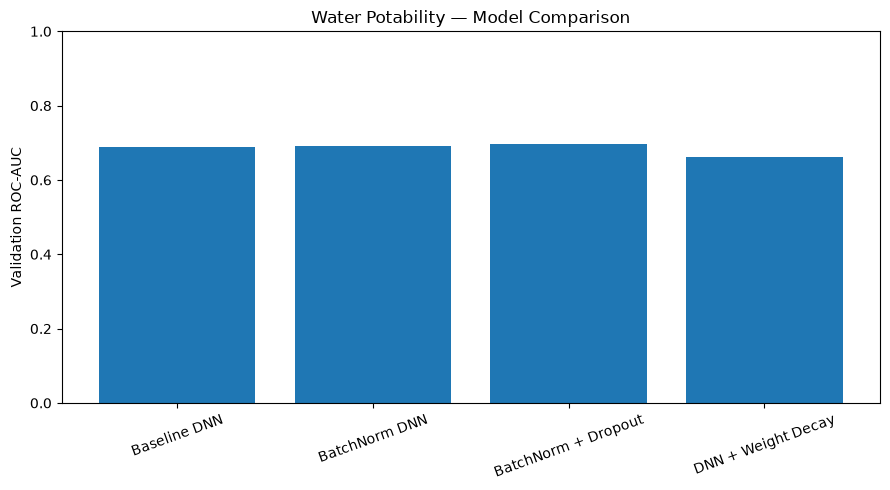

Figure saved to: c:\Users\sy_be\Projects\Water-Potability-PyTorch\images\model_comparison.png


In [10]:
import matplotlib.pyplot as plt

# Create the images directory if necessary
images_dir = project_root / "images"
images_dir.mkdir(parents=True, exist_ok=True)

# Plot validation ROC-AUC
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    results_df["Model"],
    results_df["ROC-AUC"]
)

ax.set_title("Water Potability — Model Comparison")
ax.set_ylabel("Validation ROC-AUC")
ax.set_ylim(0, 1)

ax.tick_params(axis="x", rotation=20)

plt.tight_layout()

# Save figure
figure_path = images_dir / "model_comparison.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Figure saved to: {figure_path}")

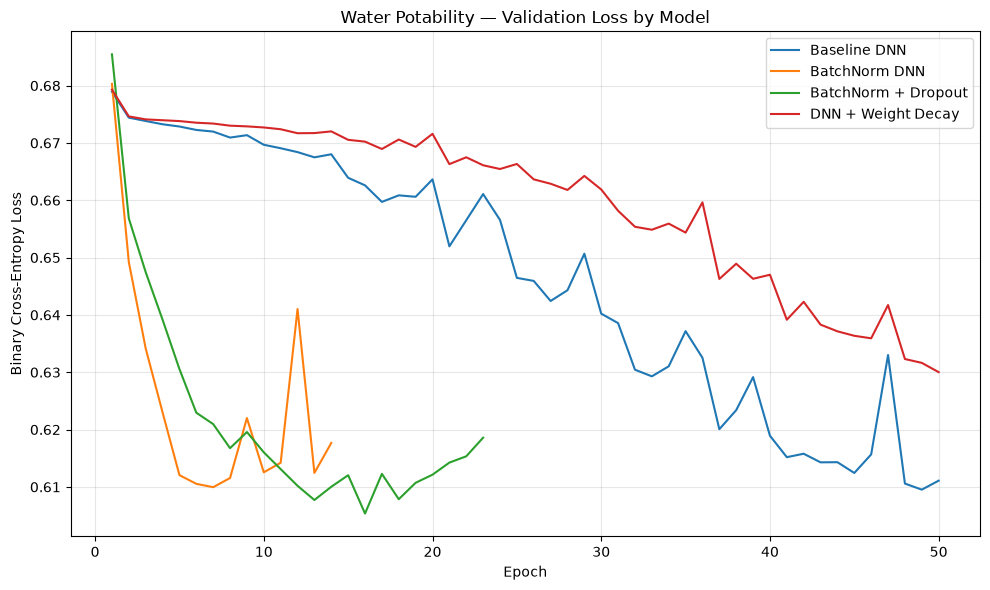

Figure saved to: c:\Users\sy_be\Projects\Water-Potability-PyTorch\images\validation_loss_comparison.png


In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

for name, history in training_histories.items():
    epochs = range(1, len(history["val"]) + 1)

    ax.plot(
        epochs,
        history["val"],
        label=name
    )

ax.set_title("Water Potability — Validation Loss by Model")
ax.set_xlabel("Epoch")
ax.set_ylabel("Binary Cross-Entropy Loss")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

figure_path = images_dir / "validation_loss_comparison.png"

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {figure_path}")